# Module: Pandas Assignments
## Lesson: Pandas

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Assignment 1: DataFrame Creation and Indexing

1. Create a Pandas DataFrame with 4 columns and 6 rows filled with random integers. Set the index to be the first column.
2. Create a Pandas DataFrame with columns 'A', 'B', 'C' and index 'X', 'Y', 'Z'. Fill the DataFrame with random integers and access the element at row 'Y' and column 'B'.

In [ ]:
df = pd.DataFrame(np.random.randint(1, 25, size=(6, 4)), columns=["A", "B", "C", "D"])
print(df)

df.set_index("A", inplace=True)
print(df)

    A   B   C   D
0  24   4  22  21
1  23   9   5  15
2  11  11  22   3
3  14  22  11  19
4   4   5  12  12
5  24   7  16  17
     B   C   D
A             
24   4  22  21
23   9   5  15
11  11  22   3
14  22  11  19
4    5  12  12
24   7  16  17


In [ ]:
df = pd.DataFrame(
    np.random.randint(1, 10, size=(3, 3)),
    columns=["A", "B", "C"],
    index=["X", "Y", "Z"],
)
print(df)
print(df.at["X", "A"])

   A  B  C
X  8  4  5
Y  3  8  6
Z  6  7  8
8


### Assignment 2: DataFrame Operations

1. Create a Pandas DataFrame with 3 columns and 5 rows filled with random integers. Add a new column that is the product of the first two columns.
2. Create a Pandas DataFrame with 3 columns and 4 rows filled with random integers. Compute the row-wise and column-wise sum.

In [4]:
df = pd.DataFrame(np.random.randint(1, 16, size=(5, 3)))
print(df)

df[3] = df[0] * df[1]
print(df)

    0   1   2
0   3   2   4
1   7  10   5
2   3   8   3
3  14   8  11
4   1  12   2
    0   1   2    3
0   3   2   4    6
1   7  10   5   70
2   3   8   3   24
3  14   8  11  112
4   1  12   2   12


In [5]:
df = pd.DataFrame(np.random.randint(1, 16, size=(4, 3)))
print(df)

print("\nrow sum\n", df.sum(axis=1))
print("column sum\n", df.sum(axis=0))

    0   1   2
0  10   9   9
1   2  13  10
2   9  12  14
3  11   6  12

row sum
 0    28
1    25
2    35
3    29
dtype: int64
column sum
 0    32
1    40
2    45
dtype: int64


### Assignment 3: Data Cleaning

1. Create a Pandas DataFrame with 3 columns and 5 rows filled with random integers. Introduce some NaN values. Fill the NaN values with the mean of the respective columns.
2. Create a Pandas DataFrame with 4 columns and 6 rows filled with random integers. Introduce some NaN values. Drop the rows with any NaN values.

In [6]:
df = pd.DataFrame(np.random.randint(-5, 10, size=(5, 3)))
print(df)

df.iloc[0, 0] = np.nan
df.iloc[2, 2] = np.nan
df.iloc[4, 1] = np.nan
print(df)

df.fillna(df.mean(), inplace=True)
print(df)

   0  1  2
0 -3  7  3
1  4 -1  8
2 -3  5  2
3  3 -2  1
4  5  7 -3
     0    1    2
0  NaN  7.0  3.0
1  4.0 -1.0  8.0
2 -3.0  5.0  NaN
3  3.0 -2.0  1.0
4  5.0  NaN -3.0
      0     1     2
0  2.25  7.00  3.00
1  4.00 -1.00  8.00
2 -3.00  5.00  2.25
3  3.00 -2.00  1.00
4  5.00  2.25 -3.00


In [7]:
df = pd.DataFrame(np.random.randint(-5, 10, size=(6, 4)))

df.iloc[0, 0] = np.nan
df.iloc[2, 2] = np.nan
df.iloc[4, 1] = np.nan

df.dropna(inplace=True)
print(df)

     0    1    2  3
1 -4.0  5.0  4.0 -2
3  1.0  4.0  7.0  2
5  5.0  4.0  5.0 -2


### Assignment 4: Data Aggregation

1. Create a Pandas DataFrame with 2 columns: 'Category' and 'Value'. Fill the 'Category' column with random categories ('A', 'B', 'C') and the 'Value' column with random integers. Group the DataFrame by 'Category' and compute the sum and mean of 'Value' for each category.
2. Create a Pandas DataFrame with 3 columns: 'Product', 'Category', and 'Sales'. Fill the DataFrame with random data. Group the DataFrame by 'Category' and compute the total sales for each category.

In [ ]:
df = pd.DataFrame(
    {
        "Category": np.random.choice(["A", "B", "C"], size=10),
        "Value": np.random.randint(1, 100, size=10),
    }
)
print(df)

df.groupby("Category")["Value"].agg(["sum", "mean"])

  Category  Value
0        B     81
1        C     52
2        C      8
3        B     83
4        C     97
5        A     58
6        A     63
7        C     18
8        A     73
9        C     74


,sum,mean
Category,,
A,194,64.666667
B,164,82.000000
C,249,49.800000


In [ ]:
df = pd.read_csv("Online Sales Data.csv")
df.head()
df = df[["Product Name", "Product Category", "Units Sold"]]
df.rename(
    {"Product Name": "Product", "Product Category": "Category", "Units Sold": "Sales"},
    axis=1,
    inplace=True,
)
df.groupby("Category")["Sales"].sum()

Category
Beauty Products    457
Books              428
Clothing           517
Electronics        422
Home Appliances    421
Sports             491
Name: Sales, dtype: int64

### Assignment 5: Merging DataFrames

1. Create two Pandas DataFrames with a common column. Merge the DataFrames using the common column.
2. Create two Pandas DataFrames with different columns. Concatenate the DataFrames along the rows and along the columns.

In [ ]:
comm_col = pd.array(np.random.randint(1, 10, size=10))
df_1 = pd.DataFrame(
    {
        "A": np.random.randint(1, 10, size=10),
        "B": np.random.randint(1, 10, size=10),
        "C": comm_col,
    }
)
df_2 = pd.DataFrame(
    {
        "D": np.random.randint(1, 10, size=10),
        "E": np.random.randint(1, 10, size=10),
        "C": comm_col,
    }
)

pd.merge(df_1, df_2, on="C")

,A,B,C,D,E
0,1,2,2,1,3
1,1,2,2,8,9
2,1,2,2,8,3
3,4,8,7,6,9
4,9,2,4,2,8
5,9,2,4,5,4
6,2,9,2,1,3
7,2,9,2,8,9
8,2,9,2,8,3
9,8,5,2,1,3


In [ ]:
df_1 = pd.DataFrame(
    {"A": np.random.randint(1, 10, size=10), "B": np.random.randint(1, 10, size=10)}
)
df_2 = pd.DataFrame(
    {"D": np.random.randint(1, 10, size=10), "E": np.random.randint(1, 10, size=10)}
)

concat_col = pd.concat([df_1, df_2], axis=1)
print(concat_col)

concat_row = pd.concat([df_1, df_2], axis=0, ignore_index=True)
print(concat_row)

   A  B  D  E
0  8  7  8  5
1  9  9  1  1
2  6  9  3  3
3  2  3  3  9
4  2  2  2  6
5  6  3  7  8
6  2  3  1  9
7  1  7  7  3
8  7  6  8  3
9  7  7  1  8
      A    B    D    E
0   8.0  7.0  NaN  NaN
1   9.0  9.0  NaN  NaN
2   6.0  9.0  NaN  NaN
3   2.0  3.0  NaN  NaN
4   2.0  2.0  NaN  NaN
5   6.0  3.0  NaN  NaN
6   2.0  3.0  NaN  NaN
7   1.0  7.0  NaN  NaN
8   7.0  6.0  NaN  NaN
9   7.0  7.0  NaN  NaN
10  NaN  NaN  8.0  5.0
11  NaN  NaN  1.0  1.0
12  NaN  NaN  3.0  3.0
13  NaN  NaN  3.0  9.0
14  NaN  NaN  2.0  6.0
15  NaN  NaN  7.0  8.0
16  NaN  NaN  1.0  9.0
17  NaN  NaN  7.0  3.0
18  NaN  NaN  8.0  3.0
19  NaN  NaN  1.0  8.0


### Assignment 6: Time Series Analysis

1. Create a Pandas DataFrame with a datetime index and one column filled with random integers. Resample the DataFrame to compute the monthly mean of the values.
2. Create a Pandas DataFrame with a datetime index ranging from '2021-01-01' to '2021-12-31' and one column filled with random integers. Compute the rolling mean with a window of 7 days.

In [12]:
df = pd.read_csv("Online Sales Data.csv")

df = df[["Date", "Units Sold"]]

df["Date"] = pd.to_datetime(df["Date"])
df.head()

df["Month"] = df["Date"].dt.month_name()

df.groupby("Month")["Units Sold"].mean()

Month
April        5.543478
August       5.196721
February     5.627119
January      5.690909
July         4.984615
June         5.622951
March        5.360000
May          5.529412
September    5.807692
Name: Units Sold, dtype: float64

In [13]:
df = pd.read_csv("Online Sales Data.csv")
df = df[["Date", "Units Sold"]]
df.set_index("Date", inplace=True)
pd.to_numeric(df["Units Sold"])
df.rolling(7).mean()

# date_rng = pd.date_range(start='2021-01-01', end='2021-12-31', freq='D')
# df = pd.DataFrame(date_rng, columns=['date'])
# df['data'] = np.random.randint(0, 100, size=(len(date_rng)))
# df.set_index('date', inplace=True)
# print("Original DataFrame:")
# print(df)
#
# # Compute the rolling mean with a window of 7 days
# rolling_mean = df.rolling(window=7).mean()
# print("Rolling mean DataFrame:")
# print(rolling_mean)

,Units Sold
Date,
2026-01-01,NaN
2026-01-02,NaN
2026-01-02,NaN
2026-01-05,NaN
2026-01-05,NaN
...,...
2026-09-29,6.714286
2026-09-29,7.285714
2026-09-29,7.000000


### Assignment 7: MultiIndex DataFrame

1. Create a Pandas DataFrame with a MultiIndex (hierarchical index). Perform some basic indexing and slicing operations on the MultiIndex DataFrame.
2. Create a Pandas DataFrame with MultiIndex consisting of 'Category' and 'SubCategory'. Fill the DataFrame with random data and compute the sum of values for each 'Category' and 'SubCategory'.

In [14]:
df = pd.read_csv("Online Sales Data.csv")
df["Date"] = pd.to_datetime(df["Date"])
df.set_index(["Transaction ID", "Date"], inplace=True)
df.loc[pd.IndexSlice[:, "2026-08-01":"2026-08-07"], :]

,,Product Category,Product Name,Units Sold,Unit Price,Total Revenue,Region,Payment Method
Transaction ID,Date,,,,,,,
10388,2026-08-01,Sports,Dumbbell Set,2,79.99,159.98,South America,PayPal
10389,2026-08-01,Electronics,Bluetooth Speaker,6,49.99,299.94,Europe,Debit Card
10390,2026-08-02,Electronics,Smartphone Case,2,14.99,29.98,Africa,Bank Transfer
10391,2026-08-02,Clothing,Denim Jacket,10,64.99,649.90,Europe,Credit Card
10392,2026-08-03,Clothing,Cotton T-Shirt,7,19.99,139.93,Africa,Bank Transfer
10393,2026-08-03,Clothing,Hoodie,10,44.99,449.90,Europe,Debit Card
10394,2026-08-04,Beauty Products,Lipstick Set,4,29.99,119.96,Oceania,Gift Card
10395,2026-08-05,Clothing,Running Shoes,2,89.99,179.98,Asia,Credit Card
10396,2026-08-06,Sports,Yoga Mat,2,25.99,51.98,Europe,Debit Card


In [15]:
df = pd.read_csv("Online Sales Data.csv")
df.set_index(["Product Category", "Product Name"], inplace=True)
df.groupby(["Product Category", "Product Name"]).sum()

Transaction ID  \
Product Category Product Name                            
Beauty Products  Face Moisturizer               153465   
                 Lipstick Set                   205419   
                 Perfume                        172204   
                 Shampoo                        163942   
                 Sunscreen SPF 50               185121   
Books            Atomic Habits                  173072   
                 Data Science Handbook          153452   
                 Deep Learning Basics           256443   
                 Python Crash Course            113471   
                 The Alchemist                   61378   
Clothing         Cotton T-Shirt                  82388   
                 Denim Jacket                   215349   
                 Hoodie                         195428   
                 Running Shoes                  215153   
                 Yoga Pants                     183478   
Electronics      Bluetooth Speaker              174378   
                 Smartphone Case                215414   
                 Smartwatch                     112337   
                 USB-C Charger                  154112   
                 Wireless Earbuds               174466   
Home Appliances  Air Fryer                      142757   
                 Blender                        214881   
                 Coffee Maker                   144532   
                 Electric Kettle                144146   
                 Vacuum Cleaner                 153664   
Sports           Dumbbell Set                   143357   
                 Resistance Bands               183780   
                 Tennis Racket                  164818   
                 Water Bottle                   287138   
                 Yoga Mat                       185707   

                                                                                     Date  \
Product Category Product Name                                                               
Beauty Products  Face Moisturizer       2026-01-212026-02-052026-02-102026-02-132026-0...   
                 Lipstick Set           2026-01-092026-02-162026-02-242026-03-062026-0...   
                 Perfume                2026-01-052026-01-052026-01-052026-01-122026-0...   
                 Shampoo                2026-01-062026-01-232026-01-262026-02-162026-0...   
                 Sunscreen SPF 50       2026-01-142026-02-052026-02-222026-03-182026-0...   
Books            Atomic Habits          2026-01-022026-01-152026-01-172026-01-312026-0...   
                 Data Science Handbook  2026-01-272026-01-272026-01-272026-02-082026-0...   
                 Deep Learning Basics   2026-01-142026-01-232026-02-022026-02-102026-0...   
                 Python Crash Course    2026-02-132026-04-102026-05-102026-06-172026-0...   
                 The Alchemist          2026-01-212026-03-162026-03-222026-05-022026-0...   
Clothing         Cotton T-Shirt         2026-02-282026-03-242026-04-292026-06-192026-0...   
                 Denim Jacket           2026-02-042026-02-062026-02-112026-02-172026-0...   
                 Hoodie                 2026-01-062026-02-012026-02-102026-02-112026-0...   
                 Running Shoes          2026-01-262026-01-282026-01-312026-03-062026-0...   
                 Yoga Pants             2026-01-022026-01-062026-01-062026-01-162026-0...   
Electronics      Bluetooth Speaker      2026-02-072026-03-082026-03-132026-03-242026-0...   
                 Smartphone Case        2026-01-202026-01-292026-02-072026-02-102026-0...   
                 Smartwatch             2026-01-202026-02-012026-02-222026-03-062026-0...   
                 USB-C Charger          2026-01-092026-01-142026-02-202026-02-242026-0...   
                 Wireless Earbuds       2026-01-182026-02-242026-03-112026-03-232026-0...   
Home Appliances  Air Fryer              2026-01-192026-02-012026-02-072026-02-112026-0...   
                 Blender                2026

### Assignment 8: Pivot Tables

1. Create a Pandas DataFrame with columns 'Date', 'Category', and 'Value'. Create a pivot table to compute the sum of 'Value' for each 'Category' by 'Date'.
2. Create a Pandas DataFrame with columns 'Year', 'Quarter', and 'Revenue'. Create a pivot table to compute the mean 'Revenue' for each 'Quarter' by 'Year'.

In [ ]:
df = pd.read_csv("Online Sales Data.csv")
pivot_table = df.pivot_table(
    values="Units Sold", index="Product Name", columns="Product Category"
)
pivot_table

Product Category,Beauty Products,Books,Clothing,Electronics,Home Appliances,Sports
Product Name,,,,,,
Air Fryer,NaN,NaN,NaN,NaN,6.000000,NaN
Atomic Habits,NaN,6.058824,NaN,NaN,NaN,NaN
Blender,NaN,NaN,NaN,NaN,5.285714,NaN
Bluetooth Speaker,NaN,NaN,NaN,5.294118,NaN,NaN
Coffee Maker,NaN,NaN,NaN,NaN,5.142857,NaN
Cotton T-Shirt,NaN,NaN,5.000000,NaN,NaN,NaN
Data Science Handbook,NaN,5.200000,NaN,NaN,NaN,NaN
Deep Learning Basics,NaN,5.960000,NaN,NaN,NaN,NaN
Denim Jacket,NaN,NaN,6.666667,NaN,NaN,NaN


In [ ]:
df = pd.read_csv("Online Sales Data.csv")
df.set_index("Transaction ID", inplace=True)
df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df["Date"].dt.year
df["Quarter"] = df["Date"].dt.quarter
quarter_sales = df.groupby(["Year", "Quarter"])["Total Revenue"].sum().reset_index()
quarter_sales.set_index("Year")
quarter_sales

,Year,Quarter,Total Revenue
0,2026,1,47875.87
1,2026,2,51964.20
2,2026,3,45281.57


Text(0.5, 1.0, 'Quarterly Revenue')

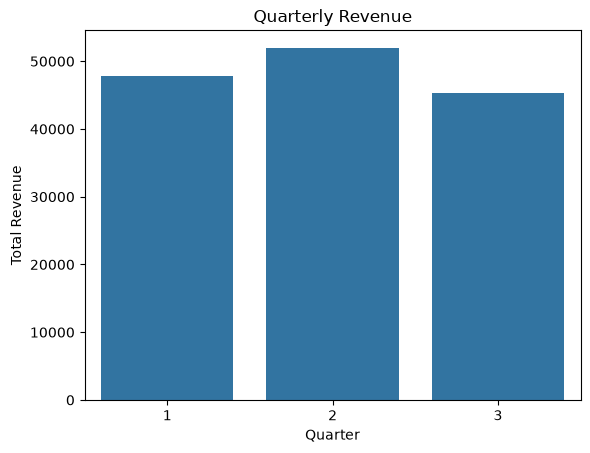

In [18]:
sns.barplot(x="Quarter", y="Total Revenue", data=quarter_sales)
plt.title("Quarterly Revenue")

### Assignment 9: Applying Functions

1. Create a Pandas DataFrame with 3 columns and 5 rows filled with random integers. Apply a function that doubles the values of the DataFrame.
2. Create a Pandas DataFrame with 3 columns and 6 rows filled with random integers. Apply a lambda function to create a new column that is the sum of the existing columns.

In [ ]:
df = pd.DataFrame(
    {
        "A": np.random.randint(1, 6, size=5),
        "B": np.random.randint(1, 6, size=5),
        "C": np.random.randint(1, 6, size=5),
    }
)

print(df)

df = df.map(lambda x: x * 2)

df

   A  B  C
0  1  3  5
1  5  3  2
2  1  4  5
3  1  3  4
4  5  4  4


,A,B,C,D
0,2,6,10,18
1,10,6,4,20
2,2,8,10,20
3,2,6,8,16
4,10,8,8,26


In [40]:
df = pd.DataFrame(
    {
        "A": np.random.randint(1, 6, size=6),
        "B": np.random.randint(1, 6, size=6),
        "C": np.random.randint(1, 6, size=6),
    }
)

print(df)

df["D"] = df.apply(axis=1, func=lambda row: row.sum())
df

   A  B  C
0  2  3  2
1  2  1  4
2  4  4  5
3  2  2  4
4  2  1  3
5  2  3  4


,A,B,C,D
0,2,3,2,7
1,2,1,4,7
2,4,4,5,13
3,2,2,4,8
4,2,1,3,6
5,2,3,4,9


### Assignment 10: Working with Text Data

1. Create a Pandas Series with 5 random text strings. Convert all the strings to uppercase.
2. Create a Pandas Series with 5 random text strings. Extract the first three characters of each string.

In [48]:
df_text = pd.Series(["apple", "banana", "cat", "dog", "elephant"])
df_text.str.upper()

0       APPLE
1      BANANA
2         CAT
3         DOG
4    ELEPHANT
dtype: str

In [49]:
df_text = pd.Series(["apple", "banana", "cat", "dog", "elephant"])
df_text.apply(lambda string: string[0:3])

0    app
1    ban
2    cat
3    dog
4    ele
dtype: str